# Python Shiny - App Template
Here we present the base mechanism for building an interactive dashboard, i.e., a [Python-Shiny dashboard](https://shiny.posit.co/py/). 

In this dashboard, we'll read the `NTL-LTER_Lake_Nutrients_PeterPaul_Processed.csv` dataset and allow the user to interactively explore nutrient values over time. The user will select which nutrient to examine from a dropdown menu, limit the time frame of data viewed by a date slider, toggle which lake(s) to view, and also toggle value for different depth classes. 

In this notebook, we'll construct, test, debug the base code before we move it over to the Shiny version. This code will include how we import the csv into a dataframe, how we query the data to mimic user queries via the dashboard widgets, and how the selected data will be plotted. 

Then we streamline the process by creating a function that accepts the variables that will become user inputs in the dashboard. 

**CONDA RECIPE**
```bash
 conda create -n env700-shiny -c conda-forge python=3.12 shiny geopandas pandas matplotlib seaborn folium mapclassify jupyterlab ipykernel ipywidgets
```

### Workspace set up 
First we import packages and read the data into a dataframe, performing any wrangling that will facilitate our work. 

In [ ]:
# Import packages
import pandas as pd
import seaborn as sns

# Set sns theme
sns.set_theme(
    style='whitegrid',
    #rc = {'axes.facecolor':'cyan'}
    )


The wrangling consists of melting (pivot to longer format) of the data so that all nutrient measurements occupy a single column with another column labeling which nutrient is being measured. This allows for easier selection. 

We also rename columns and values to make them more presentable. 

In [ ]:
# Read the data into a dataframe, pivotting nutrients into longer format
df_nutrients = pd.read_csv(
    'Data/NTL-LTER_Lake_Nutrients_PeterPaul_Processed.csv',
    dtype={'lakeid':'str'},
    parse_dates=['sampledate']
).melt(
    id_vars=['lakename', 'sampledate', 'depth_id'],
    value_vars=['tn_ug', 'tp_ug', 'nh34', 'no23'],
    var_name='nutrient',
    value_name='ug'
).rename(columns={
    'lakename':'Lake name',
    'depth_id':'Depth zone'
})

#Update nutrient values to more readable names
nutrient_name_updates = {
    'tn_ug':'Total Nitrogen',
    'tp_ug':'Total Phosphorus',
    'nh34':'Ammonia',
    'no23':'Nitrates'
}
df_nutrients['nutrient'] = df_nutrients['nutrient'].map(nutrient_name_updates)

#Display the result
df_nutrients.head()

,Lake name,sampledate,Depth zone,nutrient,ug
0,Paul Lake,1991-05-20,1,Total Nitrogen,538.0
1,Paul Lake,1991-05-20,2,Total Nitrogen,285.0
2,Paul Lake,1991-05-20,3,Total Nitrogen,399.0
3,Paul Lake,1991-05-20,4,Total Nitrogen,453.0
4,Paul Lake,1991-05-20,5,Total Nitrogen,363.0


### Filtering and plotting the data
Next, we mimic the values the user might select and write code to act on these selections. 

In [ ]:
# Set the "selected" values
start_date = "1995-01-01"
end_date = "1999-12-31"
nutrient = "Total Nitrogen"
depth_ids = [1,2,3]
lake_names = ['Peter Lake', 'Paul Lake']

# Subset the data
df_subset = df_nutrients.loc[
    (df_nutrients['sampledate'] > start_date) &  # Start date
    (df_nutrients['sampledate'] < end_date) &    # End date
    (df_nutrients['nutrient'] == nutrient) &  # Nutrient
    (df_nutrients['Depth zone']).isin(depth_ids) & # Depth IDs
    (df_nutrients['Lake name']).isin(lake_names), # Lake Names
]


### Plotting the selected records
Finally, we plot the values.

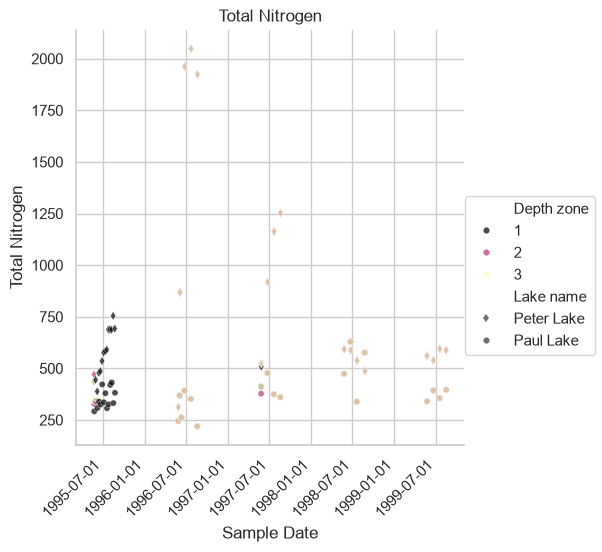

In [4]:
#Create a plot of selected nutrients by sampledate, with markers colored by depth_id using the inverse mako colormap and different shapes for lakename
the_plot = sns.relplot(
    data = df_subset,
    x='sampledate',
    y='ug',
    hue='Depth zone',
    style='Lake name',  markers=['d','o'],
    palette='magma',
    s=20,
    alpha=0.7,
)

#Set plot title and axis labels
the_plot.set_axis_labels('Sample Date', nutrient)
the_plot.set(title=f'{nutrient}')
the_plot.set_xticklabels(rotation=45, ha='right')

#Clean up the legend
sns.move_legend(
    the_plot, 
    loc = 'center right',
    frameon = True,
)

#Display
the_plot;

## Convert to a function
With our code set, we now move it into a function with inputs for each of the variables we mimicked the user providing. 

In [5]:
### Plot as a function
def plot_nutrients(start_date = "1995-01-01",
                   end_date = "1999-12-31",
                   nutrient = "Total Nitrogen",
                   depth_ids = [1,2,3],
                   lake_names = ['Peter Lake', 'Paul Lake']):
    # Subset the data
    df_subset = df_nutrients.loc[
        (df_nutrients['sampledate'] > start_date) &  # Start date
        (df_nutrients['sampledate'] < end_date) &    # End date
        (df_nutrients['nutrient'] == nutrient) &  # Nutrient
        (df_nutrients['Depth zone']).isin(depth_ids) & # Depth IDs
        (df_nutrients['Lake name']).isin(lake_names), # Lake Names
    ]

    #Create a plot of selected nutrients by sampledate, with markers colored by depth_id using the inverse mako colormap and different shapes for lakename
    the_plot = sns.relplot(
        data = df_subset,
        x='sampledate',
        y='ug',
        hue='Depth zone',
        style='Lake name',  markers=['d','o'],
        palette='magma',
        s=20,
        alpha=0.7,
    )

    #Set plot title and axis labels
    the_plot.set_axis_labels('Sample Date', nutrient)
    the_plot.set(title=f'{nutrient}')
    the_plot.set_xticklabels(rotation=45, ha='right')

    #Clean up the legend
    sns.move_legend(
        the_plot, 
        loc = 'center right',
        frameon = True,
    )

    #return the plot
    return the_plot
    

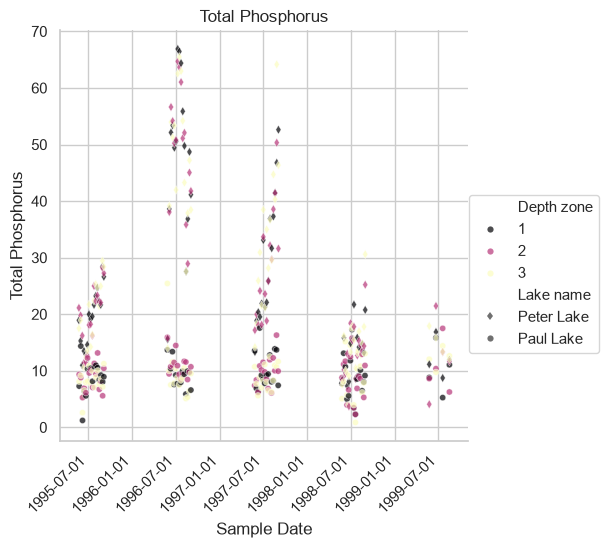

In [6]:
#Apply the function
plot_nutrients(nutrient='Total Phosphorus');

## Summary
We now have a two stage process ready for rollout: Code to set up and read the initial data, then a function to filter and plot the data. 